## Agenda

1. Recall, and `HBAR` vs `HBARPARM`
2. Checking the sums with `PROC MEANS`
3. More `PROC SGPLOT`: series, scatter, histograms, layering, and colors
4. `PROC SGPANEL`: the same plot for each group
5. Exporting plots
6. Exercise

## Recall

| | |
|---|---|
| **Conditionals** | using `IF`/`ELSE`, `IF`/`ELSE IF`/`ELSE`, and `DO` statements |
| **`PROC FREQ`** (for plotting) | displays plots alongside frequency tables |
| **`PROC SGPLOT`** | SAS procedure to create high quality graphs |

## `HBAR` vs `HBARPARM`

Here is the sum of `Damage` by `Date` plotted two ways, as horizontal bars. `xaxis min=0 max=200000` puts both plots on the same scale so we can compare them.

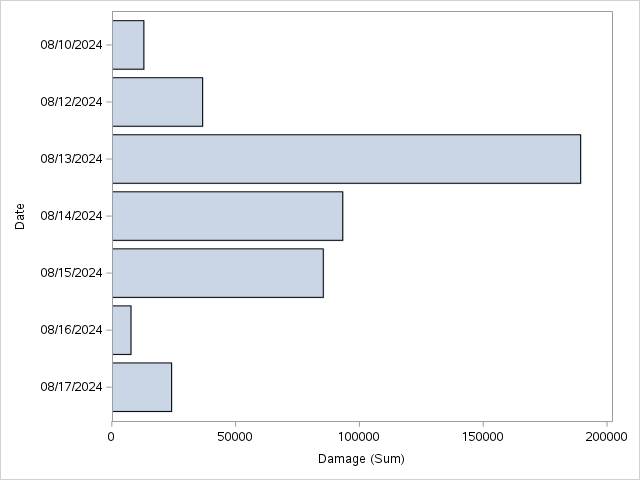

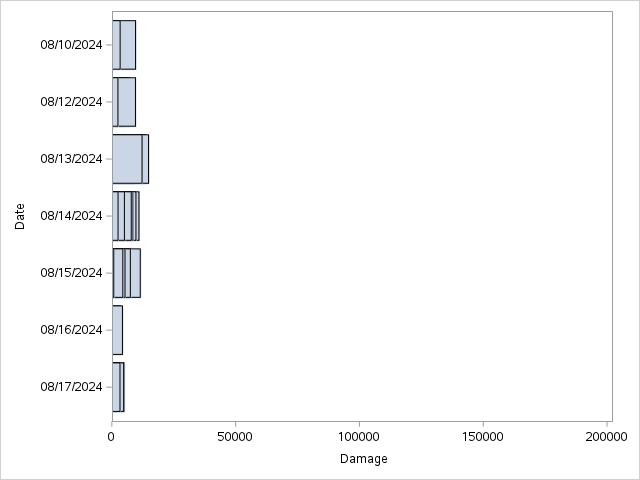

In [ ]:
libname ma505 "~";    /* skip if your autoexec does this */

/* HBAR: adds up Damage for each date */
proc sgplot data=ma505.ow_stats;
    hbar Date / response=Damage;
    xaxis min=0 max=200000;
run;

/* HBARPARM: expects one row per date */
proc sgplot data=ma505.ow_stats;
    hbarparm category=Date response=Damage;
    xaxis min=0 max=200000;
run;

The bars are very different. `HBAR` adds up all the games on each date. `HBARPARM` assumes the data is already summarized, so it draws one bar per **row** on top of each other instead of adding them.

## Verify with `PROC MEANS`

Let's check the `HBAR` totals by computing the sum of `Damage` for each date ourselves.

```{=html}
<div class="anno"><div class="anno-row"><pre class="anno-code"><span class="kw">proc means</span> data=ma505.ow_stats;
    <span class="libref-circle"><span class="kw">class</span> Date;</span><span class="anno-inline fragment"><span class="arrow-left"></span><span class="anno-inline-text">the group: one set of statistics for each date</span></span>
    <span class="libref-circle"><span class="kw">var</span> Damage;</span><span class="anno-inline fragment"><span class="arrow-left"></span><span class="anno-inline-text">the value we are interested in</span></span>
    <span class="libref-circle"><span class="kw">output</span> out=ow_sum sum=Total_Damage;</span><span class="anno-inline fragment"><span class="arrow-left"></span><span class="anno-inline-text">creates a new table <span class="mono">ow_sum</span> with the sum of <span class="mono">Damage</span> for each date, in a column called <span class="mono">Total_Damage</span></span></span>
<span class="kw">run</span>;</pre></div></div>
```

In [ ]:
/* using proc means to sum by group */
proc means data=ma505.ow_stats;
    class Date;
    var Damage;
    output out=ow_sum sum=Total_Damage;
run;

proc print data=ow_sum;
run;

The MEANS Procedure 
 
 
 
 
 Analysis Variable : Damage 
 
 
 Date 
 N Obs 
 N 
 Mean 
 Std Dev 
 Minimum 
 Maximum 
 
 
 
 
 08/10/24 
 2 
 2 
 6463.00 
 4403.86 
 3349.00 
 9577.00 
 
 
 08/12/24 
 8 
 8 
 4582.50 
 2596.79 
 1886.00 
 9540.00 
 
 
 08/13/24 
 31 
 31 
 6107.55 
 3729.03 
 1015.00 
 14824.00 
 
 
 08/14/24 
 16 
 16 
 5828.44 
 2706.82 
 1166.00 
 10948.00 
 
 
 08/15/24 
 20 
 20 
 4269.45 
 2500.85 
 773.0000000 
 11480.00 
 
 
 08/16/24 
 2 
 2 
 3863.50 
 593.2625894 
 3444.00 
 4283.00 
 
 
 08/17/24 
 8 
 8 
 3016.38 
 1296.08 
 1445.00 
 5021.00 
 
 
 
 The Print Procedure 
 
 
 
 
 Obs 
 Date 
 _TYPE_ 
 _FREQ_ 
 Total_Damage 
 
 
 
 
 1 
 . 
 0 
 87 
 449422 
 
 
 2 
 08/10/2024 
 1 
 2 
 12926 
 
 
 3 
 08/12/2024 
 1 
 8 
 36660 
 
 
 4 
 08/13/2024 
 1 
 31 
 189334 
 
 
 5 
 08/14/2024 
 1 
 16 
 93255 
 
 
 6 
 08/15/2024 
 1 
 20 
 85389 
 
 
 7 
 08/16/2024 
 1 
 2 
 7727 
 
 
 8 
 08/17/2024 
 1 
 8 
 24131

The `Total_Damage` values match the `HBAR` bars. The first row, with no `Date` and `_TYPE_` = 0, is the total across **all** dates. `_FREQ_` is the number of games in each group.

## Documentation

Each plot statement has its own page in the SAS documentation, with all of its options and examples.

| Statement | Documentation |
|---|---|
| `HBAR` | [HBAR statement](https://documentation.sas.com/doc/en/pgmsascdc/9.4_3.5/grstatproc/n1wvtdp1zvu57un1wjyheyd61e3i.htm) |
| `VBAR` | [VBAR statement](https://documentation.sas.com/doc/en/pgmsascdc/9.4_3.5/grstatproc/n0p7vdd69sgf3wn1479qxqxuryrt.htm) |
| `HBARPARM` | [HBARPARM statement](https://documentation.sas.com/doc/en/pgmsascdc/9.4_3.5/grstatproc/n0a5svhjs7b505n1vlk4kuth2x3q.htm) |
| `VBARPARM` | [VBARPARM statement](https://documentation.sas.com/doc/en/pgmsascdc/9.4_3.5/grstatproc/n0mc5dtithid5mn13c54dlgaceq3.htm) |

## Time series chart

`SERIES` connects the data with a line. It is best for time series or other ordered data.

```{=html}
<div class="anno"><div class="anno-row"><pre class="anno-code"><span class="kw">proc sgplot</span> data=sashelp.pricedata;
    <span class="kw">series</span> x=Date y=Price /
        <span class="libref-circle">group=ProductName</span><span class="anno-inline fragment"><span class="arrow-left"></span><span class="anno-inline-text">creates a different line for each value of this group</span></span>
        <span class="libref-circle"><span class="kw">markers</span></span>;<span class="anno-inline fragment"><span class="arrow-left"></span><span class="anno-inline-text">marks the data points on the line</span></span>
    <span class="kw">where</span> ProductName in (<span class="sas-str" style="color:#a31515">'Product1'</span>, <span class="sas-str" style="color:#a31515">'Product2'</span>, <span class="sas-str" style="color:#a31515">'Product3'</span>);
<span class="kw">run</span>;</pre></div></div>
```

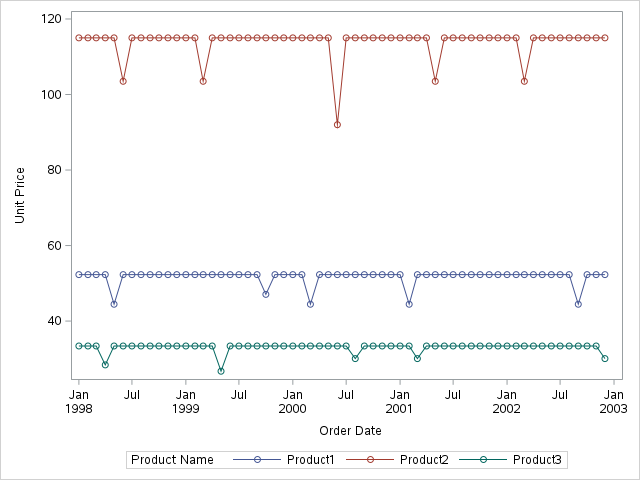

In [ ]:
proc sgplot data=sashelp.pricedata;
    series x=Date y=Price /
        group=ProductName markers;
    where ProductName in ('Product1', 'Product2', 'Product3');
run;

## Scatter plot

`SCATTER` plots one point for each row. `markerattrs=(symbol=circlefilled)` fills in the points.

```{=html}
<div class="anno"><div class="anno-row"><pre class="anno-code"><span class="kw">proc sgplot</span> data=sashelp.class;
    <span class="kw">scatter</span> x=Height y=Weight /
        group=Age <span class="libref-circle">markerattrs=(symbol=circlefilled)</span>;<span class="anno-inline fragment"><span class="arrow-left"></span><span class="anno-inline-text">fills in the data points</span></span>
<span class="kw">run</span>;</pre></div></div>
```

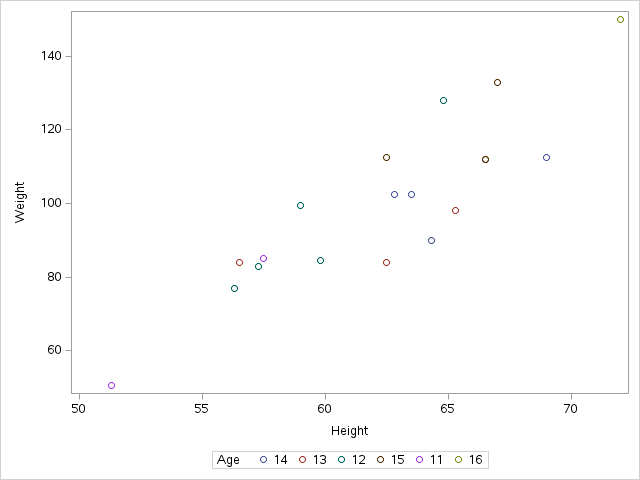

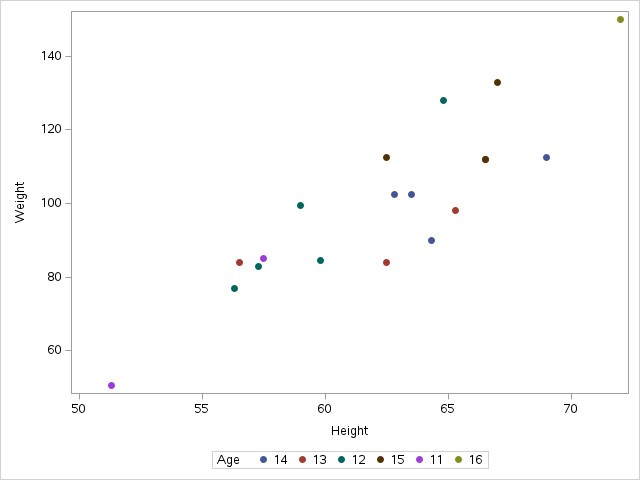

In [ ]:
/* without markerattrs */
proc sgplot data=sashelp.class;
    scatter x=Height y=Weight / group=Age;
run;

/* with markerattrs */
proc sgplot data=sashelp.class;
    scatter x=Height y=Weight /
        group=Age markerattrs=(symbol=circlefilled);
run;

## Layering: series and scatter

`SERIES ... markers` is the same as layering a `SERIES` and a `SCATTER` plot. Every plot statement in the same `PROC SGPLOT` is drawn on the same axes.

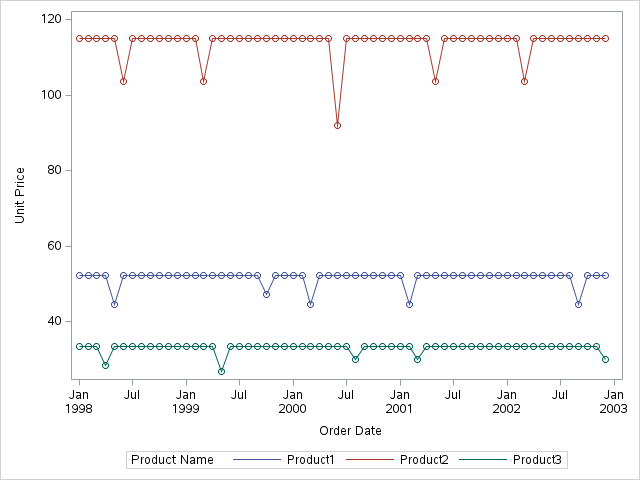

In [ ]:
/* series and scatter combined */
proc sgplot data=sashelp.pricedata;
    series x=Date y=Price / group=ProductName;
    scatter x=Date y=Price / group=ProductName;
    where ProductName in ('Product1', 'Product2', 'Product3');
run;

## Layering: histogram

`HISTOGRAM` shows the distribution of a numeric column.

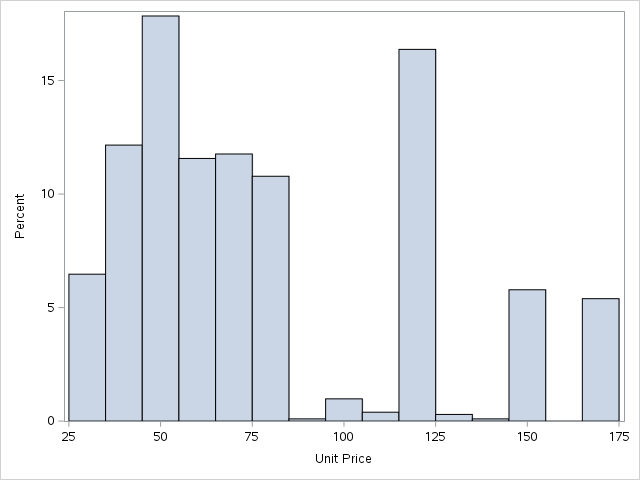

In [ ]:
proc sgplot data=sashelp.pricedata;
    histogram Price;
run;

## Layering: adding density curves

```{=html}
<div class="anno"><div class="anno-row"><pre class="anno-code"><span class="kw">proc sgplot</span> data=sashelp.pricedata;
    <span class="kw">histogram</span> Price;
    <span class="libref-circle"><span class="kw">density</span> Price;</span><span class="anno-inline fragment"><span class="arrow-left"></span><span class="anno-inline-text">the default is a <b>normal</b> curve</span></span>
    <span class="kw">density</span> Price / <span class="libref-circle">type=kernel</span>;<span class="anno-inline fragment"><span class="arrow-left"></span><span class="anno-inline-text">a <b>kernel</b> curve follows the shape of the data (non-parametric)</span></span>
<span class="kw">run</span>;</pre></div></div>
```

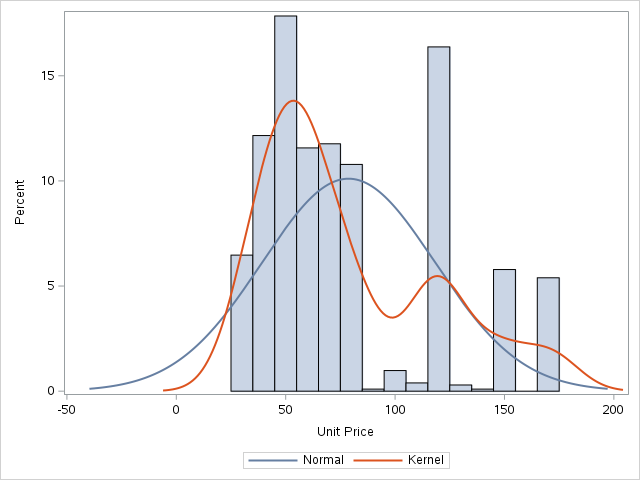

In [ ]:
proc sgplot data=sashelp.pricedata;
    histogram Price;
    density Price;
    density Price / type=kernel;
run;

## Customization: adding color

```{=html}
<div class="anno"><div class="anno-row"><pre class="anno-code"><span class="kw">proc sgplot</span> data=sashelp.pricedata;
    <span class="kw">histogram</span> Price / <span class="libref-circle">fillattrs=(color=<span class="sas-str" style="color:#a31515">"yellow"</span>) transparency=0.95</span>;<span class="anno-inline fragment"><span class="arrow-left"></span><span class="anno-inline-text">yellow bars that are very see-through</span></span>
    <span class="kw">density</span> Price / <span class="libref-circle">lineattrs=(color=<span class="sas-str" style="color:#a31515">"green"</span>)</span>;<span class="anno-inline fragment"><span class="arrow-left"></span><span class="anno-inline-text">the color of each density line</span></span>
    <span class="kw">density</span> Price / type=kernel <span class="libref-circle">lineattrs=(color=<span class="sas-str" style="color:#a31515">"pink"</span>)</span>;
    <span class="libref-circle"><span class="kw">title</span> <span class="sas-str" style="color:#a31515">'Distribution of Price Data for All Products'</span>;</span><span class="anno-inline fragment"><span class="arrow-left"></span><span class="anno-inline-text">titles the plot. <span class="mono">TITLE</span> stays on until we clear it with <span class="mono">title;</span></span></span>
<span class="kw">run</span>;
<span class="kw">title</span>;</pre></div></div>
```

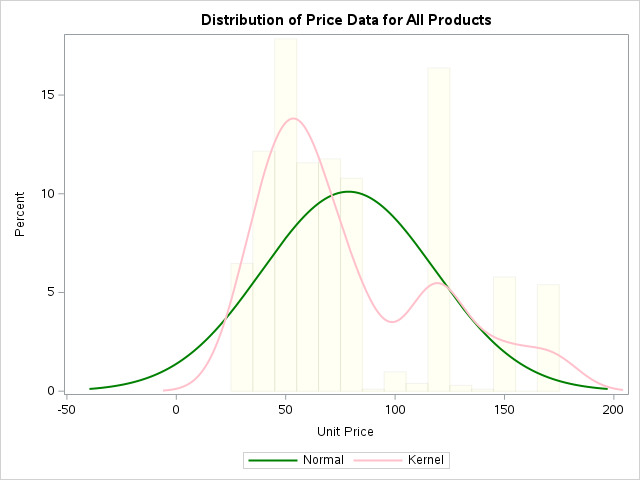

In [ ]:
proc sgplot data=sashelp.pricedata;
    histogram Price / fillattrs=(color="yellow") transparency=0.95;
    density Price / lineattrs=(color="green");
    density Price / type=kernel lineattrs=(color="pink");
    title 'Distribution of Price Data for All Products';
run;
title;

## `PROC SGPANEL`

`PROC SGPANEL` makes **multi-panel** plots: the same plot for each group, in separate panels in one layout.

With `PANELBY`, we can compare patterns across groups. Each panel shows the same plot type (like a histogram or scatter plot) for a different subset of the data.

## A scatter plot by region with `SGPLOT`

First, one scatter plot with every region together. The colors help, but it's hard to compare regions.

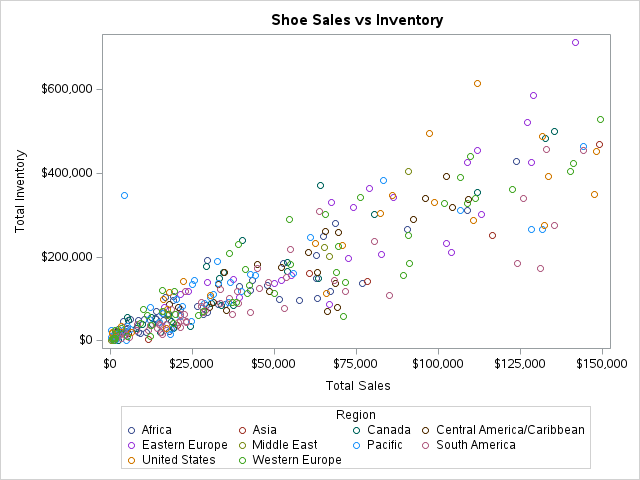

In [ ]:
proc sgplot data=sashelp.shoes;
    scatter x=Sales y=Inventory / group=Region;
    where Sales < 150000;
    title 'Shoe Sales vs Inventory';
run;
title;

## Panel by region with `SGPANEL`

```{=html}
<div class="anno"><div class="anno-row"><pre class="anno-code"><span class="kw">proc sgpanel</span> data=sashelp.shoes;
    <span class="libref-circle"><span class="kw">panelby</span> Region / rows=2 columns=5;</span><span class="anno-inline fragment"><span class="arrow-left"></span><span class="anno-inline-text">one panel for each <span class="mono">Region</span>, in 2 rows and 5 columns (the layout is optional)</span></span>
    <span class="kw">scatter</span> x=Sales y=Inventory / group=Region;
    <span class="kw">where</span> Sales &lt; 150000;
<span class="kw">run</span>;</pre></div></div>
```

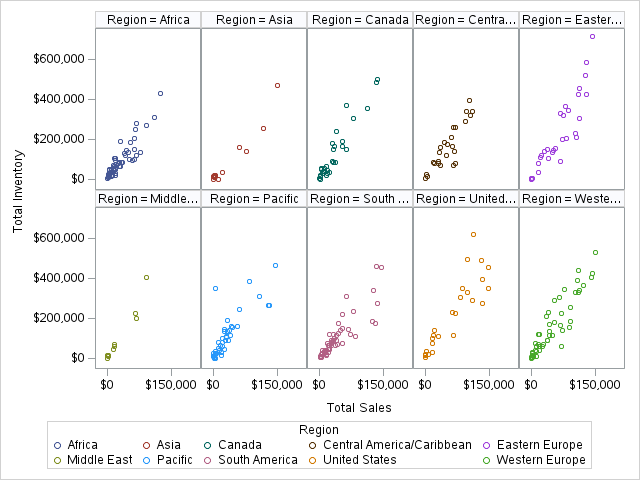

In [ ]:
proc sgpanel data=sashelp.shoes;
    panelby Region / rows=2 columns=5;
    scatter x=Sales y=Inventory / group=Region;
    where Sales < 150000;
run;

## `PANELBY` with two variables

```{=html}
<div class="anno"><div class="anno-row"><pre class="anno-code"><span class="kw">proc sgpanel</span> data=sashelp.shoes;
    <span class="kw">panelby</span> Region Product / <span class="libref-circle">layout=lattice</span> rows=8;<span class="anno-inline fragment"><span class="arrow-left"></span><span class="anno-inline-text">a grid: one row or column for each variable. Only allowed with <b>two</b> <span class="mono">PANELBY</span> variables.</span></span>
    <span class="kw">histogram</span> Inventory;
    <span class="kw">where</span> Region in (<span class="sas-str" style="color:#a31515">'Pacific'</span>, <span class="sas-str" style="color:#a31515">'United States'</span>);
<span class="kw">run</span>;</pre></div></div>
```

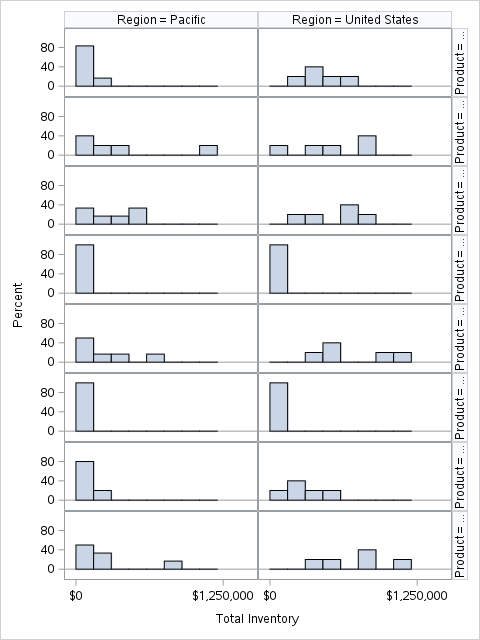

In [ ]:
proc sgpanel data=sashelp.shoes;
    panelby Region Product / layout=lattice rows=8;
    histogram Inventory;
    where Region in ('Pacific', 'United States');
run;

## Exporting results

We can export our plots using **ODS Graphics**. It can save many kinds of files: PDF, PNG, JPG, SVG, and more.

```{=html}
<div class="anno"><div class="anno-row"><pre class="anno-code"><span class="libref-circle"><span class="kw">ods graphics</span> / reset imagename=<span class="sas-str" style="color:#a31515">"Inventory_Distribution"</span> imagefmt=png</span>
    width=800px height=1200px;<span class="anno-inline fragment"><span class="arrow-left"></span><span class="anno-inline-text"><span class="mono">reset</span> clears other ODS Graphics settings, <span class="mono">imagename</span> is the file name, and <span class="mono">imagefmt</span> is the file type</span></span>
<span class="libref-circle"><span class="kw">ods listing</span> gpath=<span class="sas-str" style="color:#a31515">"~"</span>;</span><span class="anno-inline fragment"><span class="arrow-left"></span><span class="anno-inline-text">the folder to save to. <span class="mono">~</span> is your home folder.</span></span>

<span class="kw">title</span> <span class="sas-str" style="color:#a31515">'Shoe Inventory Distribution in the Pacific and United States'</span>;
<span class="kw">proc sgpanel</span> data=sashelp.shoes;
    <span class="kw">panelby</span> Region Product / layout=lattice rows=8;
    <span class="kw">histogram</span> Inventory;
    <span class="kw">where</span> Region in (<span class="sas-str" style="color:#a31515">'Pacific'</span>, <span class="sas-str" style="color:#a31515">'United States'</span>);
<span class="kw">run</span>;

<span class="libref-circle"><span class="kw">ods listing close</span>;</span><span class="anno-inline fragment"><span class="arrow-left"></span><span class="anno-inline-text">always close the listing so the file saves properly</span></span>
<span class="kw">ods graphics</span> / reset;
<span class="kw">title</span>;</pre></div></div>
```

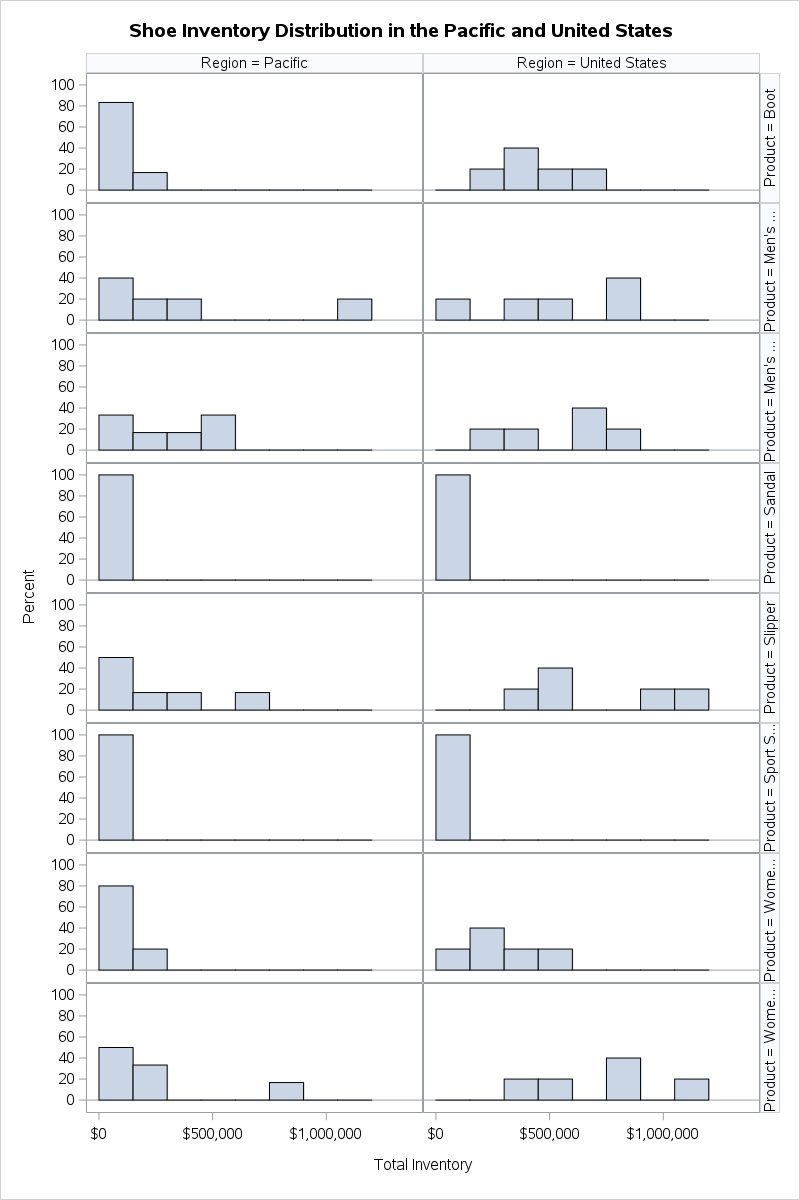

In [ ]:
ods graphics / reset imagename="Inventory_Distribution" imagefmt=png
    width=800px height=1200px;
ods listing gpath="~";

title 'Shoe Inventory Distribution in the Pacific and United States';
proc sgpanel data=sashelp.shoes;
    panelby Region Product / layout=lattice rows=8;
    histogram Inventory;
    where Region in ('Pacific', 'United States');
run;

ods listing close;
ods graphics / reset;    /* back to the default size and names */
title;

Refresh **Server Files and Folders** and look in your home folder for `Inventory_Distribution.png`.

## Exercise

Use the Overwatch stats table `ma505.ow_stats`.

1. Make a scatter plot with `Damage` on the x-axis and `Heals` on the y-axis. Color the points by `Role` and fill in the markers.
2. Use `PROC SGPANEL` to make a histogram of `Damage` for each `Player`. Layer a kernel density curve on top.
3. Give the panel plot a title, and clear the title after.
    a. What do you notice about each player's damage?

<div class="solution-start"></div>


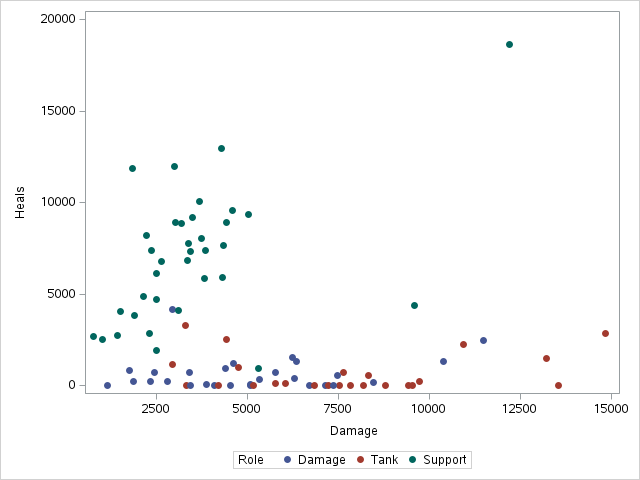

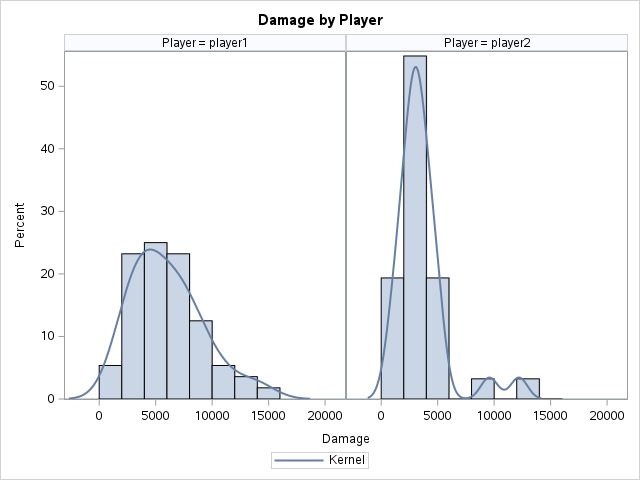

In [ ]:
libname ma505 "~";    /* skip if your autoexec does this */

/* 1. scatter plot colored by role */
proc sgplot data=ma505.ow_stats;
    scatter x=Damage y=Heals /
        group=Role markerattrs=(symbol=circlefilled);
run;

/* 2 and 3. one histogram per player, with a kernel density curve */
title 'Damage by Player';
proc sgpanel data=ma505.ow_stats;
    panelby Player;
    histogram Damage;
    density Damage / type=kernel;
run;
title;

- **Scatter plot:** the roles separate clearly. Support games have high heals and lower damage. Damage and Tank games have almost no heals, and Tanks reach the highest damage.
- **Panel plot:** player1's damage is spread out, mostly between about 2,500 and 10,000. player2's damage is bunched tightly around 2,500 to 5,000, with a couple of high games around 10,000 to 12,500. That fits player2 mostly playing Support.
